# 04 - Cohort retention

**Question:** Do users come back after their first observed visit?

**Definitions**
- **Cohort month**: the month of a user's *first observed* event in the sample. A November "new" user may be an old customer whose history is simply outside the sample.
- **Retained in month N**: at least one event (any event, not a purchase) in that calendar month.
- **Incomplete windows**: the sample ends on 2021-01-31. A user first seen on 20 January has had only 11 days to return, so late cohorts look worse than they are. Unobserved periods are shown blank, never as 0%.

In [1]:
# --- Setup: run this cell first ---
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "productpulse").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from productpulse import data, metrics, charts

charts.apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

print(data.data_banner())

Real BigQuery export loaded from: C:\Users\Padmashree\OneDrive\Desktop\ProductPulse-AI\ProductPulse-AI\data\exports


In [2]:
fact, dim = data.load_model()
cohort_sql = data.load("cohort_retention_monthly")
LAST_DAY = fact["event_dt"].max()
PERIOD = f"{fact['event_dt'].min().date()} to {LAST_DAY.date()}"

## 1. Monthly cohort table (Python) and reconciliation with SQL

In [3]:
cohort = metrics.cohort_retention(fact, dim)
display(cohort.style.format({"cohort_month": lambda d: d.strftime("%Y-%m"), "active_users": "{:,.0f}",
                             "cohort_users": "{:,.0f}", "retention_rate": "{:.2%}"}))

merged = cohort.merge(cohort_sql, on=["cohort_month", "month_number"], suffixes=("_py", "_sql"), how="outer")
mismatch = merged[(merged["active_users_py"] != merged["active_users_sql"]) |
                  (merged["cohort_users_py"] != merged["cohort_users_sql"])]
assert mismatch.empty, f"Python and SQL cohort tables differ:\n{mismatch}"
assert cohort.loc[cohort["month_number"] == 0, "cohort_users"].sum() == dim["user_pseudo_id"].nunique()
print("PASS: Python cohort table equals the SQL export, and cohort sizes add up to all users.")

,cohort_month,month_number,active_users,cohort_users,retention_rate
0,2020-11,0,"79,421","79,421",100.00%
1,2020-11,1,"4,651","79,421",5.86%
2,2020-11,2,"1,204","79,421",1.52%
3,2020-12,0,"99,664","99,664",100.00%
4,2020-12,1,"2,517","99,664",2.53%
5,2021-01,0,"91,069","91,069",100.00%


PASS: Python cohort table equals the SQL export, and cohort sizes add up to all users.


## 2. Retention heatmap

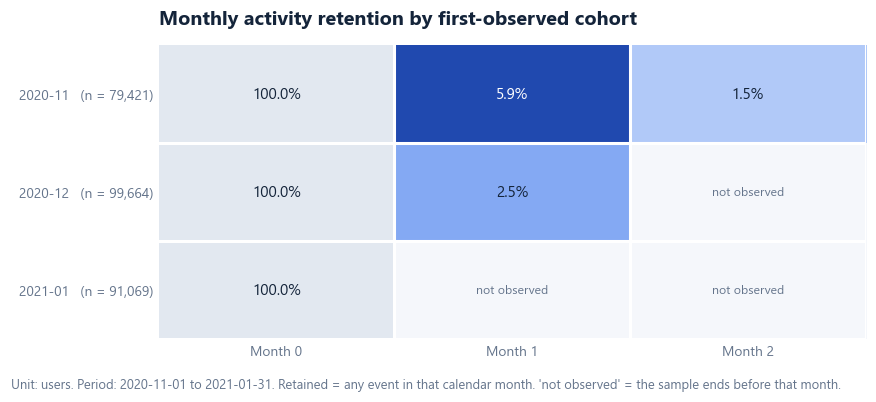

Cohort 2020-11: 79,421 users; last possible join date leaves 62 to 91 days of follow-up
Cohort 2020-12: 99,664 users; last possible join date leaves 31 to 61 days of follow-up
Cohort 2021-01: 91,069 users; last possible join date leaves 0 to 30 days of follow-up


In [4]:
matrix = metrics.cohort_matrix(cohort)
sizes = cohort[cohort["month_number"] == 0].assign(
    label=lambda d: d["cohort_month"].dt.strftime("%Y-%m")).set_index("label")["cohort_users"]

fig, ax = charts.cohort_heatmap(matrix, sizes, "Monthly activity retention by first-observed cohort")
charts.note(fig, f"Unit: users. Period: {PERIOD}. Retained = any event in that calendar month. "
                 "'not observed' = the sample ends before that month.")
charts.save_figure(fig, "04_cohort_heatmap")
plt.show()

for label in matrix.index:
    start = pd.Timestamp(label + "-01")
    print(f"Cohort {label}: {sizes.loc[label]:,} users; last possible join date leaves "
          f"{(LAST_DAY - (start + pd.offsets.MonthEnd(0))).days} to {(LAST_DAY - start).days} days of follow-up")

**Interpretation (write this yourself after running on the real export)**

- *Observation:* month-1 retention for each cohort, with cohort size, and which cells are not observed.
- *Possible explanation (unproven):* a merchandise store is visited occasionally, so low monthly return rates may be normal for this product.
- *Next check:* use the fixed 30-day window below, which treats every user equally, before comparing cohorts.

## 3. A fairer measure: return within 30 days

Calendar-month retention depends on *when in the month* a user arrived. A fixed window fixes that:

- **Eligible users**: first seen at least 30 days before the sample ends (so everyone has a full 30-day window).
- **Returned within 30 days**: active on any day 1 to 30 after their first day.

Eligible users (first seen on or before 2021-01-01): 181,033 of 270,154
Returned within 30 days: 11.96% (21,660 / 181,033), 95% CI 11.82% to 12.11%
Excluded as incomplete: 89,121 users first seen in the last 30 days


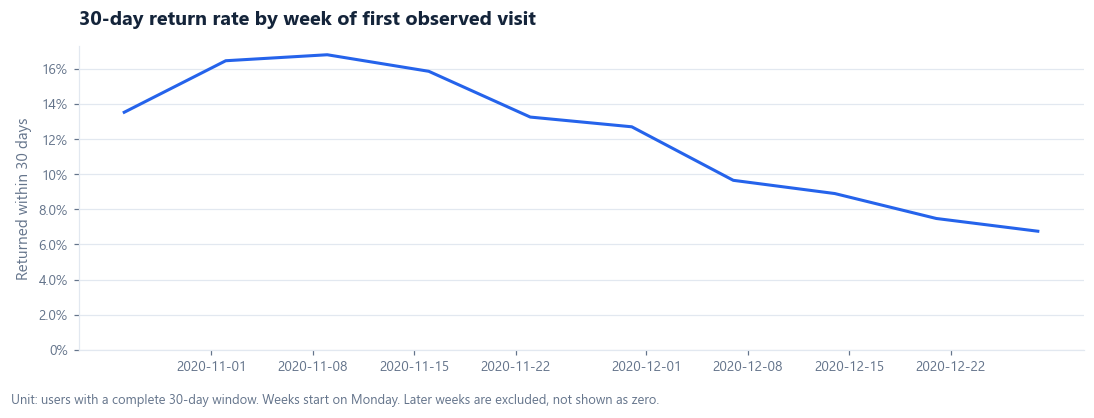

,first_week,users,returned,return_rate_30d
0,2020-10-26,"2,365",320,13.53%
1,2020-11-02,"19,374","3,190",16.47%
2,2020-11-09,"16,232","2,728",16.81%
3,2020-11-16,"18,167","2,882",15.86%
4,2020-11-23,"20,072","2,661",13.26%
5,2020-11-30,"22,034","2,799",12.70%
6,2020-12-07,"28,545","2,756",9.65%
7,2020-12-14,"24,839","2,211",8.90%
8,2020-12-21,"17,430","1,304",7.48%
9,2020-12-28,"11,975",809,6.76%


In [5]:
first_seen = dim.set_index("user_pseudo_id")["first_seen_dt"]
f = fact[["user_pseudo_id", "event_dt"]].copy()
f["days_since_first"] = (f["event_dt"] - f["user_pseudo_id"].map(first_seen)).dt.days
returned_ids = f.loc[f["days_since_first"].between(1, 30), "user_pseudo_id"].unique()

users = dim.copy()
users["eligible_30d"] = users["first_seen_dt"] <= LAST_DAY - pd.Timedelta(days=30)
users["returned_30d"] = users["user_pseudo_id"].isin(returned_ids)
eligible = users[users["eligible_30d"]]

rate = eligible["returned_30d"].mean()
lo, hi = metrics.wilson_interval(int(eligible["returned_30d"].sum()), len(eligible))
print(f"Eligible users (first seen on or before {(LAST_DAY - pd.Timedelta(days=30)).date()}): {len(eligible):,} "
      f"of {len(users):,}")
print(f"Returned within 30 days: {rate:.2%} ({int(eligible['returned_30d'].sum()):,} / {len(eligible):,}), "
      f"95% CI {lo:.2%} to {hi:.2%}")
print(f"Excluded as incomplete: {len(users) - len(eligible):,} users first seen in the last 30 days")

weekly = (eligible.assign(first_week=eligible["first_seen_dt"].dt.to_period("W-SUN").dt.start_time)
          .groupby("first_week").agg(users=("returned_30d", "size"), returned=("returned_30d", "sum")).reset_index())
weekly["return_rate_30d"] = weekly["returned"] / weekly["users"]
fig, ax = charts.line_chart(weekly, "first_week", "return_rate_30d",
                            "30-day return rate by week of first observed visit", "Returned within 30 days", percent=True)
charts.note(fig, "Unit: users with a complete 30-day window. Weeks start on Monday. Later weeks are excluded, not shown as zero.")
charts.save_figure(fig, "04_return_rate_30d_by_week")
plt.show()
display(weekly.style.format({"first_week": lambda d: d.strftime("%Y-%m-%d"), "users": "{:,.0f}",
                             "returned": "{:,.0f}", "return_rate_30d": "{:.2%}"}))

## 4. Segment comparison (eligible users only)

,device_category,users,returned,return_rate_30d,ci_low,ci_high
0,desktop,"105,294","12,515",11.89%,11.69%,12.08%
1,mobile,"71,689","8,653",12.07%,11.83%,12.31%
2,tablet,"4,050",492,12.15%,11.18%,13.19%


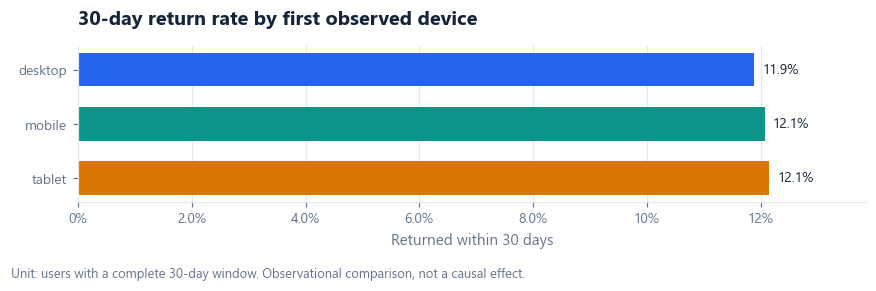

,channel_group,users,returned,return_rate_30d,ci_low,ci_high
2,Organic search,"67,903","7,854",11.57%,11.33%,11.81%
1,Direct,"42,825","5,138",12.00%,11.69%,12.31%
3,Other,"31,267","3,321",10.62%,10.28%,10.97%
5,Referral,"27,090","3,440",12.70%,12.31%,13.10%
4,Paid search,"9,553","1,089",11.40%,10.78%,12.05%
0,Data deleted,"2,395",818,34.15%,32.28%,36.08%


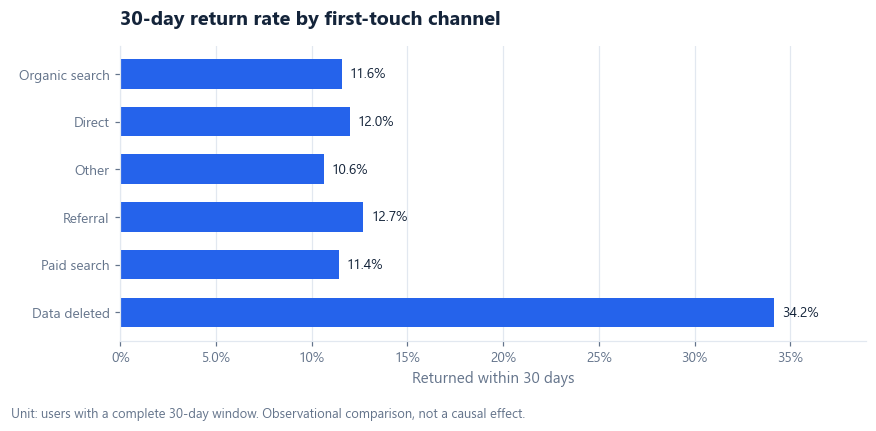

In [6]:
def segment_return(column, top=8):
    g = eligible.groupby(column).agg(users=("returned_30d", "size"), returned=("returned_30d", "sum")).reset_index()
    g = g.sort_values("users", ascending=False).head(top)
    g["return_rate_30d"] = g["returned"] / g["users"]
    g[["ci_low", "ci_high"]] = [metrics.wilson_interval(int(r), int(n)) for r, n in zip(g["returned"], g["users"])]
    return g

for column, title in [("device_category", "30-day return rate by first observed device"),
                      ("channel_group", "30-day return rate by first-touch channel")]:
    seg = segment_return(column)
    display(seg.style.format({"users": "{:,.0f}", "returned": "{:,.0f}", "return_rate_30d": "{:.2%}",
                              "ci_low": "{:.2%}", "ci_high": "{:.2%}"}))
    colours = [charts.DEVICE_COLOURS.get(v, charts.BLUE) for v in seg[column]] if column == "device_category" else None
    fig, ax = charts.bar_chart(seg[column], seg["return_rate_30d"], title, "Returned within 30 days", percent=True, colours=colours)
    charts.note(fig, "Unit: users with a complete 30-day window. Observational comparison, not a causal effect.")
    charts.save_figure(fig, f"04_return_rate_by_{column}")
    plt.show()

**Interpretation (write this yourself after running on the real export)**

- *Observation:* which device and channel have the highest and lowest 30-day return rate, with denominators and intervals.
- *Possible explanation (unproven):* returning visitors may prefer typing the address (Direct) or using a saved desktop bookmark.
- *Next check:* check whether the differences survive when you hold the cohort week constant.

## 5. Repeat activity and repeat purchase\nRepeat *activity* (coming back on another day) is not the same as a repeat *purchase*.

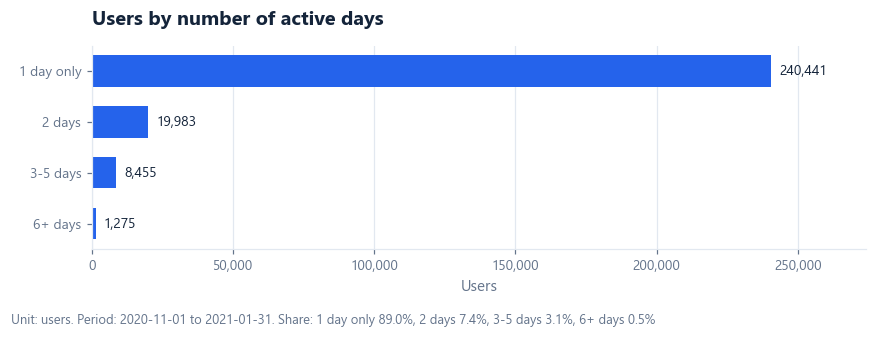

Users with a validated order: 3,702
Users with 2+ validated orders: 439 (11.86% of buyers)


In [7]:
per_user = fact.groupby("user_pseudo_id").agg(active_days=("event_dt", "nunique"), orders=("transactions", "sum"))
buckets = pd.cut(per_user["active_days"], [0, 1, 2, 5, np.inf], labels=["1 day only", "2 days", "3-5 days", "6+ days"])
dist = buckets.value_counts().reindex(["1 day only", "2 days", "3-5 days", "6+ days"])
fig, ax = charts.bar_chart(dist.index, dist.values, "Users by number of active days", "Users")
charts.note(fig, f"Unit: users. Period: {PERIOD}. Share: " + ", ".join(f"{k} {v / dist.sum():.1%}" for k, v in dist.items()))
charts.save_figure(fig, "04_active_days")
plt.show()

buyers = per_user[per_user["orders"] >= 1]
repeat = (buyers["orders"] >= 2).sum()
print(f"Users with a validated order: {len(buyers):,}")
print(f"Users with 2+ validated orders: {repeat:,} ({metrics.safe_div(repeat, len(buyers)):.2%} of buyers)")

## Limits of this analysis

- Three months of data give at most two follow-up months, for one cohort only.
- "First observed" is not "first ever". The November cohort mixes genuinely new and long-standing users.
- Retention here means *any activity*. It says nothing about satisfaction or purchases.
- `user_pseudo_id` is a browser/device identifier. A person who clears cookies or switches device looks like a new user who never returned, which pushes retention **down**.